# Erklärbarkeit von Bildklassifikation & Modellunsicherheit
**VGG-16 + Probly (MC Dropout) · shapiq (k-SII auf 4×4-Patches) · Credal Sets**

Dieses Notebook verbindet drei Säulen:
1. **MC Dropout** mit `probly.transformation.dropout(p=0.3)` auf den FC-Schichten von VGG-16 ($T=30$ stochastische Durchläufe).
2. **Räumliche Attribution** mit `shapiq`: Das Bild wird in $n=16$ Patches zerlegt, ein Spiel $v(S)$ blendet Patches ausserhalb von $S$ durch Grauwerte aus. Berechnet werden Shapley-Werte $\phi_i$ und Paar-Interaktionen $\phi_{i,j}$ (**k-SII**, `max_order=2`).
3. **Credal Sets**: Intervall $[\underline P, \overline P]$ der Klassenwahrscheinlichkeit über die $T$ Durchläufe; die Breite $\Delta P$ misst die epistemische Uneinigkeit.

**Testbilder** (im Arbeitsverzeichnis bzw. `IMG_DIR`): `GoldenRetriever.jpeg` (eindeutig), `DogCat.jpeg` (Klassenkonflikt), `blurryFrog.jpeg` (OOD / Blur).

> **Laufzeit:** Jede Koalitionsauswertung = 1 VGG-Forward + 30 billige Classifier-Pässe. Mit `BUDGET=2000` sind das ca. 2000 Auswertungen pro Bild (Wahrscheinlichkeits- und Entropie-Spiel teilen sich dank Cache dieselben Koalitionen). Auf CPU einige Minuten pro Bild, auf GPU Sekunden.

## Section 1 – Setup, Dependencies & VGG-16 Probly-Model
Installation (einmalig): `pip install torch torchvision probly shapiq matplotlib pillow`.

**MC Dropout-Konstruktion:** Der Conv-Teil von VGG-16 ist deterministisch und wird pro Bild nur **einmal** berechnet. Stochastisch ist nur der Classifier-Kopf. Wir entfernen zuerst die in VGG-16 eingebauten `Dropout(0.5)`-Schichten (sonst Doppel-Dropout) und lassen `probly.transformation.dropout(p=0.3)` den Dropout einfügen. Danach werden alle Dropout-Module im Train-Modus gehalten, während der Rest im Eval-Modus bleibt:
$$\hat p_t(y\mid x)=\mathrm{softmax}\big(f_{\theta,\,m_t}(x)\big),\qquad m_t\sim\mathrm{Bernoulli},\; t=1,\dots,T.$$

In [5]:
import copy, time, warnings
from pathlib import Path

import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import probly
from probly.transformation import dropout
import shapiq

# ---- Konfiguration -------------------------------------------------------
T        = 15            # MC-Dropout-Durchläufe
P_DROP   = 0.3           # Dropout-Rate (probly)
GRID     = 4             # 4x4-Gitter -> n = 16 Spieler
N_PLAYERS = GRID * GRID
BUDGET   = 500          # Koalitions-Budget für shapiq
SEED     = 42
BATCH    = 16            # Koalitionen pro Forward-Batch
IMG_DIR  = Path("Pictures")     # Ordner mit den 3 Bildern
IMAGES   = {"Golden Retriever (eindeutig)": "GoldenRetriever.jpeg",
            "Hund + Katze (Konflikt)":      "DogCat.jpeg",
            "Verschwommener Frosch (OOD)":  "blurryFrog.jpeg"}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED); np.random.seed(SEED)
print(f"torch {torch.__version__} | shapiq {shapiq.__version__} | probly {probly.__version__} | device: {DEVICE}")

torch 2.10.0+cu128 | shapiq 1.8.0 | probly 0.9.2.dev66+g01c3510f3.d20261109 | device: cpu


In [6]:
weights    = models.VGG16_Weights.DEFAULT
CATEGORIES = weights.meta["categories"]
vgg = models.vgg16(weights=weights).eval()

# Conv-Teil: deterministisch -> pro Bild nur 1x berechnen
backbone = nn.Sequential(vgg.features, vgg.avgpool, nn.Flatten()).to(DEVICE).eval()

# Classifier: eingebaute Dropout(0.5) entfernen, dann probly-MC-Dropout(p=0.3) einfügen
head = copy.deepcopy(vgg.classifier)
for i, m in enumerate(head):
    if isinstance(m, nn.Dropout):
        head[i] = nn.Identity()
head = dropout(head, p=P_DROP).to(DEVICE).eval()

def enable_mc_dropout(module):
    # Dropout-Module im Train-Modus halten (stochastische Inferenz), Rest bleibt eval.
    n = 0
    for m in module.modules():
        if isinstance(m, nn.modules.dropout._DropoutNd):
            m.train(); n += 1
    return n

n_do = enable_mc_dropout(head)
print(head)
print(f"\n{n_do} Dropout-Module aktiv, p = {[m.p for m in head.modules() if isinstance(m, nn.modules.dropout._DropoutNd)]}")
assert n_do > 0, "probly hat keine Dropout-Module eingefügt - Architektur oben prüfen."

class MCDropoutVGG:
    # Kapselt VGG-16 + probly-MC-Dropout-Kopf. predict_T liefert Wahrscheinlichkeiten (T, B, C).
    def __init__(self, backbone, head, T): self.backbone, self.head, self.T = backbone, head, T
    @torch.no_grad()
    def predict_T(self, x):
        feats = self.backbone(x.to(DEVICE))                               # (B, 25088)
        B = feats.shape[0]
        rep = feats.unsqueeze(0).expand(self.T, -1, -1).reshape(self.T * B, -1)
        return F.softmax(self.head(rep), dim=-1).view(self.T, B, -1).cpu()  # jede Zeile eigene Dropout-Maske

mc = MCDropoutVGG(backbone, head, T)

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Identity()
  (3_0): Dropout(p=0.3, inplace=False)
  (3_1): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Identity()
  (6_0): Dropout(p=0.3, inplace=False)
  (6_1): Linear(in_features=4096, out_features=1000, bias=True)
)

2 Dropout-Module aktiv, p = [0.3, 0.3]


## Section 2 – Image Pipeline & Patch-Imputations-Game
**Pipeline:** Laden → Resize $224\times224$ → ImageNet-Normalisierung.

**Patch-Maskierung:** Spieler $i\in\{0,\dots,15\}$ entspricht Patch (Zeile $i//4$, Spalte $i\bmod 4$), je $56\times56$ Pixel. Für eine Koalition $S$ bleiben die Patches in $S$ erhalten, alle anderen werden mit Grau ($0.5$ im Pixelraum, nach Normalisierung konstant pro Kanal) imputiert: $x_S = x\odot m_S + g\odot(1-m_S)$.

**Nutzenfunktion** `VisionUncertaintyGame(shapiq.Game)`, mit $T$ stochastischen Pässen $p_t(\cdot\mid x_S)$ und $\bar p=\frac1T\sum_t p_t$:
- `mode="prob"`: $v(S)=\bar p(Y=c\mid x_S)$ (Zielklasse $c$)
- `mode="entropy"`: $v(S)=H(Y\mid x_S)=-\sum_k \bar p_k\log\bar p_k$ (prädiktive Entropie, nats)
- `mode="credal"` (Zusatz): $v(S)=\Delta P_c(x_S)$

Alle Statistiken einer Koalition werden aus **denselben** $T$ Pässen berechnet und in einem gemeinsamen Cache abgelegt. Das Wahrscheinlichkeits- und das Entropie-Spiel kosten daher nur einmal Rechenzeit, wenn shapiq (fester `random_state`) dieselben Koalitionen samplet.

In [7]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
to_tensor = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
normalize = transforms.Normalize(MEAN, STD)

def load_image(path):
    # -> (normalisierter Tensor (3,224,224), uint8-Array (224,224,3) zur Anzeige)
    img = Image.open(path).convert("RGB")
    t = to_tensor(img)
    return normalize(t), (t.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

def entropy(p, axis=-1, eps=1e-12):
    return -(p * np.log(p + eps)).sum(axis=axis)

# Grau (0.5) im normalisierten Raum
GRAY = ((torch.tensor(0.5) - torch.tensor(MEAN)) / torch.tensor(STD)).view(3, 1, 1)
PS = 224 // GRID  # Patch-Grösse (56 px)

def coalition_to_pixel_mask(coalitions):
    # bool (B, 16) -> bool (B, 1, 224, 224)
    m = torch.as_tensor(coalitions, dtype=torch.float32).view(-1, 1, GRID, GRID)
    return m.repeat_interleave(PS, 2).repeat_interleave(PS, 3).bool()

STAT = ["prob", "entropy", "lower", "upper", "credal", "aleatoric", "epistemic"]

class VisionUncertaintyGame(shapiq.Game):
    # v(S) auf maskierten Bildern; mode in {'prob','entropy','credal'}; cache wird zwischen Spielen geteilt.
    def __init__(self, model, x, target, mode="prob", cache=None, batch=BATCH):
        super().__init__(n_players=N_PLAYERS, normalize=False, verbose=False)
        assert mode in {"prob", "entropy", "credal"}
        self.model, self.x, self.target, self.mode, self.batch = model, x, target, mode, batch
        self.cache = {} if cache is None else cache

    def _stats(self, coalitions):
        mask = coalition_to_pixel_mask(coalitions)
        xs = torch.where(mask, self.x.unsqueeze(0), GRAY.unsqueeze(0))               # (B,3,224,224)
        P = self.model.predict_T(xs).numpy()                                         # (T,B,C)
        pc, pm = P[:, :, self.target], P.mean(0)                                     # (T,B), (B,C)
        H, Ha = entropy(pm), entropy(P).mean(0)                                      # total / aleatorisch
        return np.stack([pm[:, self.target], H, pc.min(0), pc.max(0),
                         pc.max(0) - pc.min(0), Ha, H - Ha], axis=1)                 # (B, 7)

    def value_function(self, coalitions):
        coalitions = np.asarray(coalitions, dtype=bool)
        keys = [c.tobytes() for c in coalitions]
        todo = list(dict.fromkeys(k for k in keys if k not in self.cache))
        row = {c.tobytes(): c for c in coalitions}
        for i in range(0, len(todo), self.batch):
            chunk = todo[i:i + self.batch]
            S = self._stats(np.stack([row[k] for k in chunk]))
            for k, s in zip(chunk, S): self.cache[k] = s
        col = STAT.index(self.mode)
        return np.array([self.cache[k][col] for k in keys])

Golden Retriever (eindeutig)     -> Top-1: golden retriever             p̄ = 0.927
Hund + Katze (Konflikt)          -> Top-1: golden retriever             p̄ = 0.253
Verschwommener Frosch (OOD)      -> Top-1: langur                       p̄ = 0.295


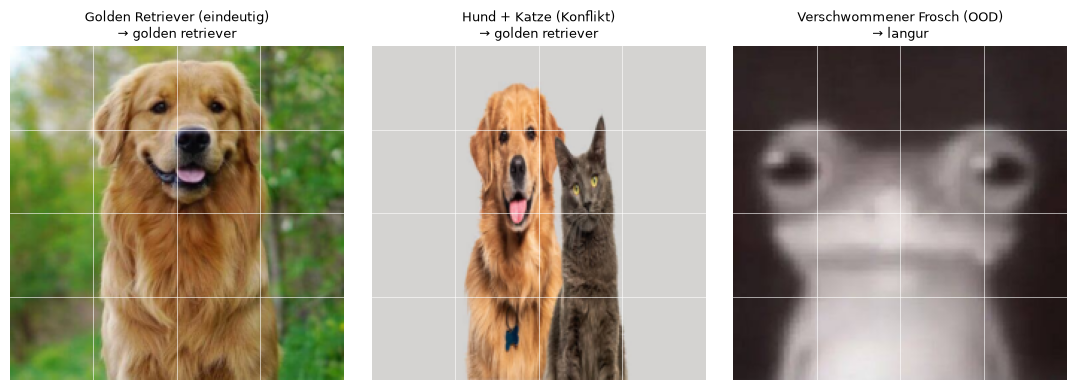

v(∅) = [0.00035153] | v(N) = [0.9344368]


In [8]:
data = {}
for name, fn in IMAGES.items():
    path = IMG_DIR / fn
    if not path.exists():
        raise FileNotFoundError(f"{path} nicht gefunden - Bild ablegen oder IMG_DIR anpassen.")
    x, img = load_image(path)
    pT = mc.predict_T(x[None])[:, 0, :].numpy()          # (T, C) volles Bild
    target = int(pT.mean(0).argmax())
    data[name] = dict(x=x, img=img, pT=pT, target=target, cache={})
    print(f"{name:32s} -> Top-1: {CATEGORIES[target]:28s} p̄ = {pT.mean(0)[target]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
for a, (n, d) in zip(ax, data.items()):
    a.imshow(d["img"]); a.set_title(f"{n}\n→ {CATEGORIES[d['target']]}", fontsize=9); a.axis("off")
    for k in range(1, GRID):  # Patch-Gitter
        a.axhline(k * PS - .5, c="w", lw=.6, alpha=.7); a.axvline(k * PS - .5, c="w", lw=.6, alpha=.7)
plt.tight_layout(); plt.show()

# Sanity-Check: Spiel für das erste Bild
g = VisionUncertaintyGame(mc, data[next(iter(data))]["x"], data[next(iter(data))]["target"])
print("v(∅) =", g(np.zeros((1, N_PLAYERS), bool)), "| v(N) =", g(np.ones((1, N_PLAYERS), bool)))

## Section 3 – Quantifizierung von Credal Sets & Unsicherheit
Aus den $T$ Pässen $P_t(Y=c\mid X)$ wird für jede Klasse $c$ das Intervall
$$\underline P(Y=c\mid X)=\min_{t=1..T}P_t(Y=c\mid X),\qquad \overline P(Y=c\mid X)=\max_{t=1..T}P_t(Y=c\mid X),\qquad \Delta P=\overline P-\underline P .$$
Zusätzlich die Entropie-Zerlegung der $T$ Pässe:
$$\underbrace{H(\bar p)}_{\text{total}}=\underbrace{\tfrac1T\sum_t H(p_t)}_{\text{aleatorisch}}+\underbrace{H(\bar p)-\tfrac1T\sum_t H(p_t)}_{\text{epistemisch (mutual information)}}.$$
*Hinweis:* Min/Max über nur $T=30$ Samples ist ein extremwertbasierter, mit $T$ wachsender Schätzer des Credal-Intervalls und rauschempfindlich; er ist als Uneinigkeitsmass zu lesen, nicht als formale Garantie.

Bild                            Klasse                         p̄   P_low    P_up      ΔP       H  H_alea      MI
Golden Retriever (eindeutig)    golden retriever            0.927   0.878   0.972   0.094   0.547   0.534   0.013
Hund + Katze (Konflikt)         golden retriever            0.253   0.127   0.389   0.261   3.166   3.070   0.097
Verschwommener Frosch (OOD)     langur                      0.295   0.165   0.487   0.322   3.394   3.307   0.086


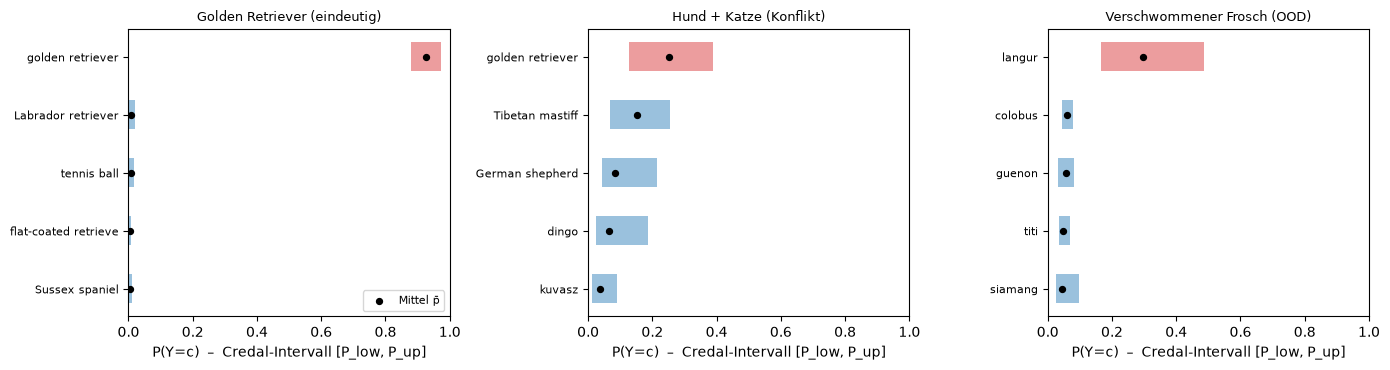

In [9]:
def credal_summary(pT, target):
    pc, pm = pT[:, target], pT.mean(0)
    H, Ha = entropy(pm), entropy(pT).mean()
    return dict(p_mean=pm[target], lower=pc.min(), upper=pc.max(), width=pc.max() - pc.min(),
                H=H, aleatoric=Ha, epistemic=H - Ha)

summary = {n: credal_summary(d["pT"], d["target"]) for n, d in data.items()}
print(f"{'Bild':32s}{'Klasse':26s}{'p̄':>7s}{'P_low':>8s}{'P_up':>8s}{'ΔP':>8s}{'H':>8s}{'H_alea':>8s}{'MI':>8s}")
for n, s in summary.items():
    print(f"{n:32s}{CATEGORIES[data[n]['target']][:24]:26s}{s['p_mean']:7.3f}{s['lower']:8.3f}{s['upper']:8.3f}"
          f"{s['width']:8.3f}{s['H']:8.3f}{s['aleatoric']:8.3f}{s['epistemic']:8.3f}")

# Intervall-Plot: Top-5-Klassen je Bild, Zielklasse hervorgehoben
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for a, (n, d) in zip(axes, data.items()):
    pT = d["pT"]; top = np.argsort(-pT.mean(0))[:5][::-1]
    lo, hi, mu = pT[:, top].min(0), pT[:, top].max(0), pT[:, top].mean(0)
    cols = ["C3" if k == d["target"] else "C0" for k in top]
    a.barh(range(5), hi - lo, left=lo, color=cols, alpha=.45, height=.5)
    a.scatter(mu, range(5), c="k", zorder=3, s=18, label="Mittel p̄")
    a.set_yticks(range(5)); a.set_yticklabels([CATEGORIES[k][:20] for k in top], fontsize=8)
    a.set_title(n, fontsize=9); a.set_xlabel("P(Y=c)  –  Credal-Intervall [P_low, P_up]"); a.set_xlim(0, 1)
axes[0].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

### 3.1 Credal Sets im Simplex (Top-3-Klassen)
Analog zur 2nd-order-Darstellung (Stichproben → Credal Set): Für jedes Bild werden die $T$ Vorhersagen $p_t$ auf die drei wahrscheinlichsten Klassen $(a,b,c)$ eingeschränkt und renormalisiert, $\tilde p_t=(p_{t,a},p_{t,b},p_{t,c})/\sum_{k\in\{a,b,c\}}p_{t,k}$, und im Dreiecks-Simplex gezeichnet:
- **Punkte:** die $T$ stochastischen Vorhersagen (2nd-order-Stichprobe)
- **Raute:** Mittelwert $\bar p$ (0th-order-Punktvorhersage)
- **Schattierte Fläche:** Credal Set als **konvexe Hülle** der Stichproben, $\mathrm{CH}\{\tilde p_1,\dots,\tilde p_T\}$

Die Fläche der Hülle ist ein zweidimensionales Mass für die epistemische Uneinigkeit (Flächenanteil am Gesamtsimplex wird im Titel angegeben). Die Hülle über nur $T=30$ Punkte ist eine Näherung und unterschätzt das wahre Credal Set.

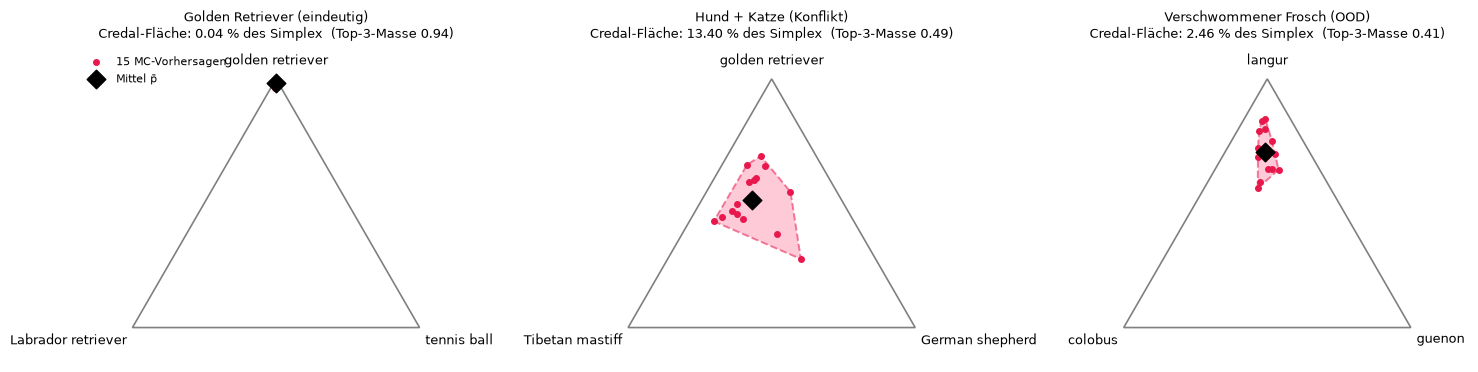

In [10]:
from scipy.spatial import ConvexHull

V = np.array([[0.5, np.sqrt(3) / 2], [0.0, 0.0], [1.0, 0.0]])   # Ecken: oben, links unten, rechts unten

def to_xy(P):                                                    # (N,3) auf dem Simplex -> (N,2)
    return P @ V

def plot_simplex(ax, pT, cats, title):
    top = np.argsort(-pT.mean(0))[:3]
    sub = pT[:, top]; mass = sub.sum(1).mean()
    sub, mean = sub / sub.sum(1, keepdims=True), (pT[:, top] / pT[:, top].sum(1, keepdims=True)).mean(0)
    xy, mxy = to_xy(sub), to_xy(mean[None])[0]
    ax.fill(*V.T, color="none", ec="0.5", lw=1.2)                # Simplex-Rahmen
    area = np.nan
    try:                                                         # Credal Set = konvexe Hülle
        hull = ConvexHull(xy); poly = xy[hull.vertices]
        ax.fill(*poly.T, color="#ff9fb8", alpha=.55, ec="#e8184d", lw=1.4, ls="--", zorder=2)
        area = hull.volume / (np.sqrt(3) / 4)                    # Anteil an der Simplex-Fläche
    except Exception:                                            # degeneriert (z. B. alle Punkte identisch)
        pass
    ax.scatter(*xy.T, s=16, c="#e8184d", zorder=3, label=f"{len(pT)} MC-Vorhersagen")
    ax.scatter(*mxy, s=90, marker="D", c="k", zorder=4, label="Mittel p̄")
    for (x, y), c, (dx, dy, ha) in zip(V, top, [(0, .04, "center"), (-.02, -.02, "right"), (.02, -.02, "left")]):
        ax.text(x + dx, y + dy, cats[c][:22], ha=ha, va="bottom" if dy > 0 else "top", fontsize=9)
    ax.set_title(f"{title}\nCredal-Fläche: {'n/a' if np.isnan(area) else f'{100*area:.2f} %'} des Simplex"
                 f"  (Top-3-Masse {mass:.2f})", fontsize=9)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_ylim(-.12, .98); ax.set_xlim(-.2, 1.2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (n, d) in zip(axes, data.items()):
    plot_simplex(a, d["pT"], CATEGORIES, n)
axes[0].legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## Section 4 – Local Feature Attribution & k-SII-Interaktionen mit `shapiq`
Für jedes Bild und **beide** Nutzenfunktionen (Klassenwahrscheinlichkeit, prädiktive Entropie) berechnen wir mit `shapiq.AgnosticExplainer` (generischer Explainer für beliebige `Game`-Objekte; ein `Explainer(model=game)`-Aufruf wird in shapiq 1.x nicht an ihn dispatcht) den Index **k-SII** mit `max_order=2`:
$$\phi_i\ \text{(Einzelbeitrag)},\qquad \phi_{i,j}\ \text{(Paar-Interaktion; }>0\text{: Synergie, }<0\text{: Redundanz)}.$$
`budget=2000` von $2^{16}=65\,536$ möglichen Koalitionen. Ein fester `random_state` sorgt dafür, dass beide Spiele dieselben Koalitionen auswerten (Cache-Treffer). Hinweis: `sample_size`/`TabularExplainer` sind für Tabellenmodelle gedacht und hier nicht nötig, da das Spiel direkt über Koalitionen definiert ist.

In [11]:
MODES = {"prob": "Klassenwahrscheinlichkeit P(Y=c)", "entropy": "Prädiktive Entropie H(Y|X_S)"}
results = {}   # results[bild][mode] = InteractionValues

for n, d in data.items():
    t0, results[n] = time.time(), {}
    for mode in MODES:
        game = VisionUncertaintyGame(mc, d["x"], d["target"], mode=mode, cache=d["cache"])
        explainer = shapiq.AgnosticExplainer(game, index="k-SII", max_order=2, random_state=SEED)
        results[n][mode] = explainer.explain(budget=BUDGET, random_state=SEED)
    print(f"{n:32s} fertig in {time.time()-t0:6.1f}s | Cache: {len(d['cache'])} Koalitionen")

def phi(iv):  # -> (φ_i als 4x4, φ_ij als 16x16-Matrix)
    return iv.get_n_order_values(1).reshape(GRID, GRID), iv.get_n_order_values(2)

# Top-3 Patches pro Bild und Spiel
for n in data:
    for mode in MODES:
        p1, _ = phi(results[n][mode]); idx = np.argsort(-np.abs(p1.ravel()))[:3]
        print(f"{n[:28]:28s} {mode:8s} Baseline v(∅)={results[n][mode].baseline_value:+.3f} | "
              + ", ".join(f"P{i}(r{i//GRID},c{i%GRID})={p1.ravel()[i]:+.3f}" for i in idx))

Golden Retriever (eindeutig)     fertig in  143.5s | Cache: 500 Koalitionen
Hund + Katze (Konflikt)          fertig in  116.0s | Cache: 500 Koalitionen
Verschwommener Frosch (OOD)      fertig in  112.8s | Cache: 500 Koalitionen
Golden Retriever (eindeutig) prob     Baseline v(∅)=+0.000 | P1(r0,c1)=+0.576, P6(r1,c2)=+0.292, P2(r0,c2)=+0.181
Golden Retriever (eindeutig) entropy  Baseline v(∅)=+5.981 | P1(r0,c1)=-3.437, P6(r1,c2)=-1.939, P2(r0,c2)=-1.876
Hund + Katze (Konflikt)      prob     Baseline v(∅)=+0.000 | P5(r1,c1)=+0.233, P6(r1,c2)=+0.090, P1(r0,c1)=+0.080
Hund + Katze (Konflikt)      entropy  Baseline v(∅)=+5.961 | P6(r1,c2)=-3.296, P9(r2,c1)=-1.770, P1(r0,c1)=-1.358
Verschwommener Frosch (OOD)  prob     Baseline v(∅)=+0.000 | P4(r1,c0)=-0.110, P6(r1,c2)=-0.108, P7(r1,c3)=-0.099
Verschwommener Frosch (OOD)  entropy  Baseline v(∅)=+5.957 | P10(r2,c2)=-0.834, P8(r2,c0)=+0.796, P4(r1,c0)=+0.750


## Section 5 – Visuelle Aufbereitung & Heatmaps
**5.1** Patch-Heatmaps der Einzelbeiträge $\phi_i$ (Rot = positiv, Blau = negativ; symmetrische Farbskala je Zeile), Zeilen = Bilder, Spalten = Nutzenfunktion.
**5.2** Interaktions-Netzwerke (`shapiq.network_plot`) der 2-Wege-Interaktionen $\phi_{i,j}$.
**5.3** Credal-Breite $\Delta P$ vs. Entropie: hohes $H$ bei kleinem $\Delta P$ spricht für *aleatorische* Unsicherheit (die Pässe stimmen überein, die Verteilung ist aber flach), hohes $\Delta P$ bzw. MI für *epistemische* Uneinigkeit des Modells.

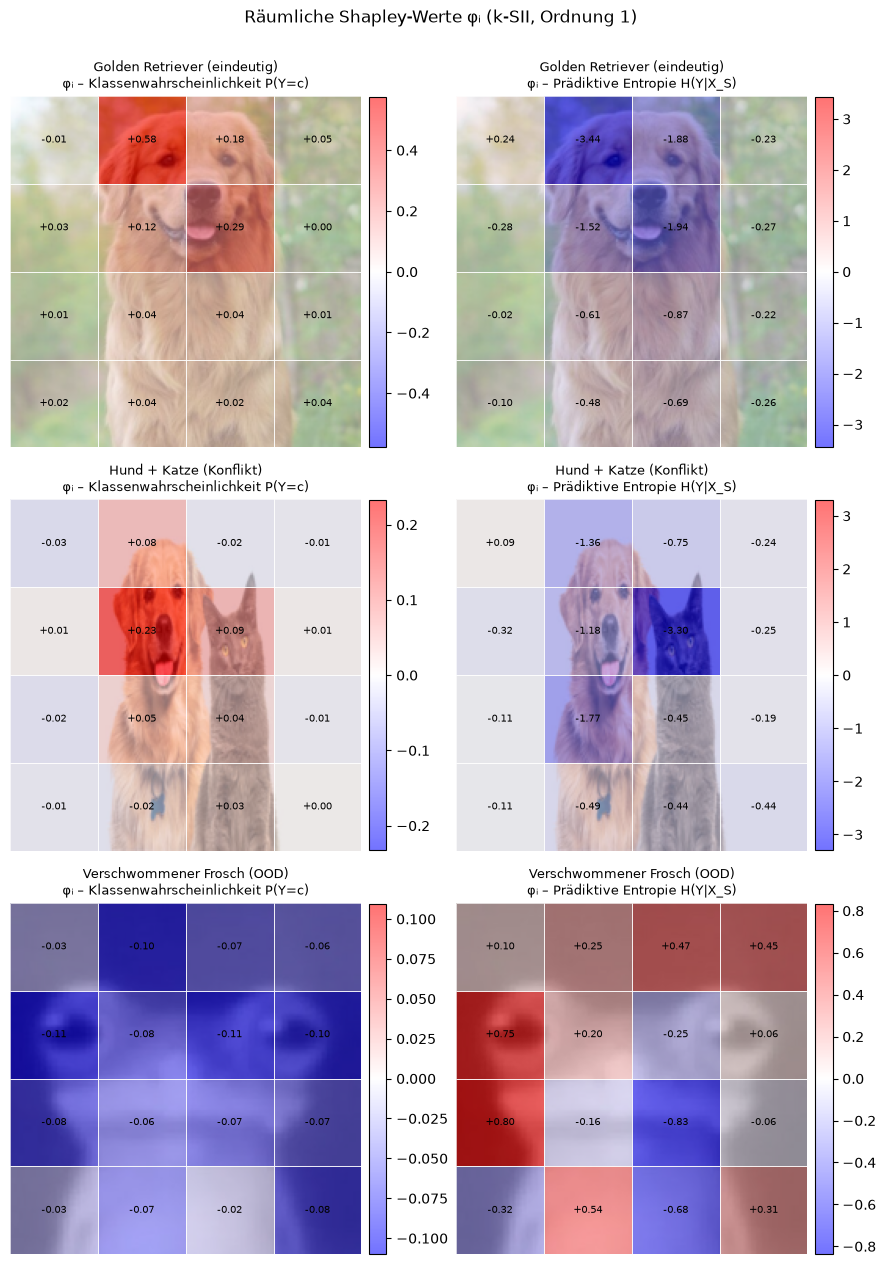

In [12]:
# 5.1 Patch-Heatmaps ---------------------------------------------------------
def overlay(ax, img, vals, vmax, title):
    ax.imshow(img, extent=(0, 224, 224, 0))
    im = ax.imshow(vals, cmap="bwr", vmin=-vmax, vmax=vmax, alpha=.55, extent=(0, 224, 224, 0), interpolation="nearest")
    for r in range(GRID):
        for c in range(GRID):
            ax.add_patch(Rectangle((c*PS, r*PS), PS, PS, fill=False, ec="w", lw=.5))
            ax.text(c*PS + PS/2, r*PS + PS/2, f"{vals[r, c]:+.2f}", ha="center", va="center", fontsize=7, color="k")
    ax.set_title(title, fontsize=9); ax.axis("off"); return im

fig, axes = plt.subplots(len(data), 2, figsize=(9, 4.2 * len(data)))
for row, (n, d) in enumerate(data.items()):
    vals = {m: phi(results[n][m])[0] for m in MODES}
    for col, m in enumerate(MODES):
        vmax = np.abs(vals[m]).max() + 1e-9
        im = overlay(axes[row, col], d["img"], vals[m], vmax, f"{n}\nφᵢ – {MODES[m]}")
        fig.colorbar(im, ax=axes[row, col], fraction=.046, pad=.02)
plt.suptitle("Räumliche Shapley-Werte φᵢ (k-SII, Ordnung 1)", y=1.002); plt.tight_layout(); plt.show()

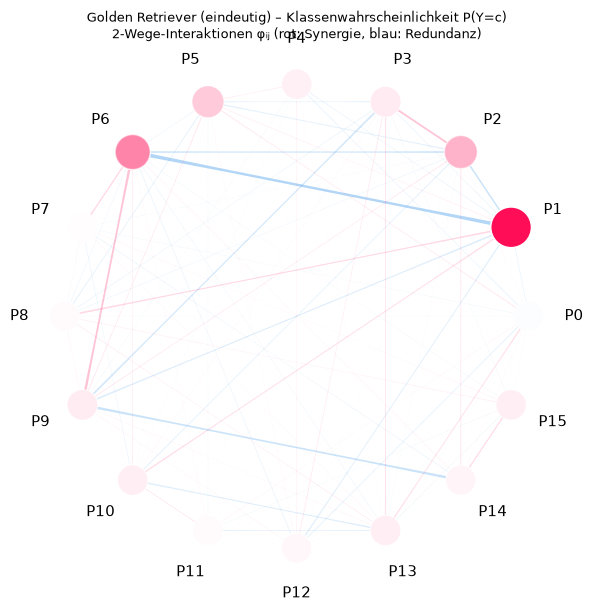

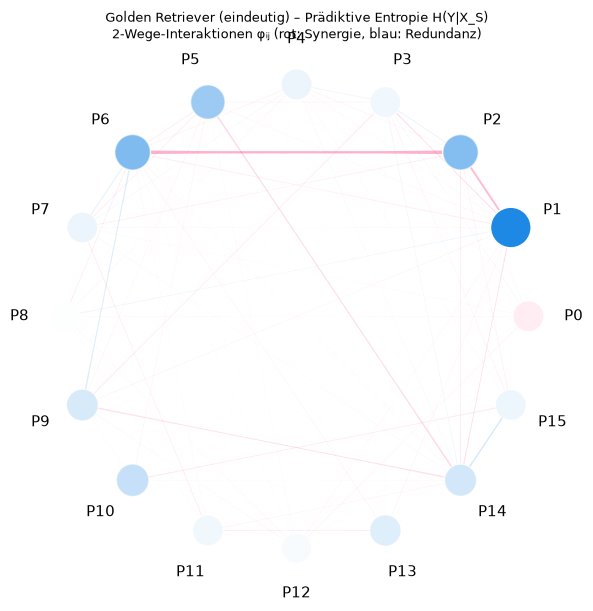

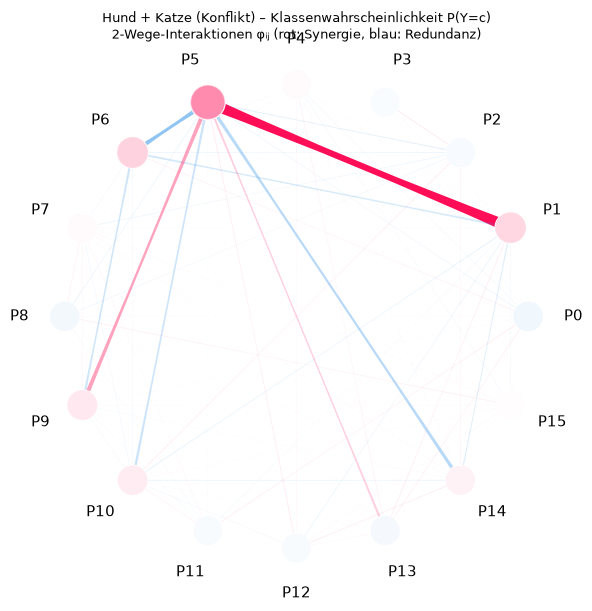

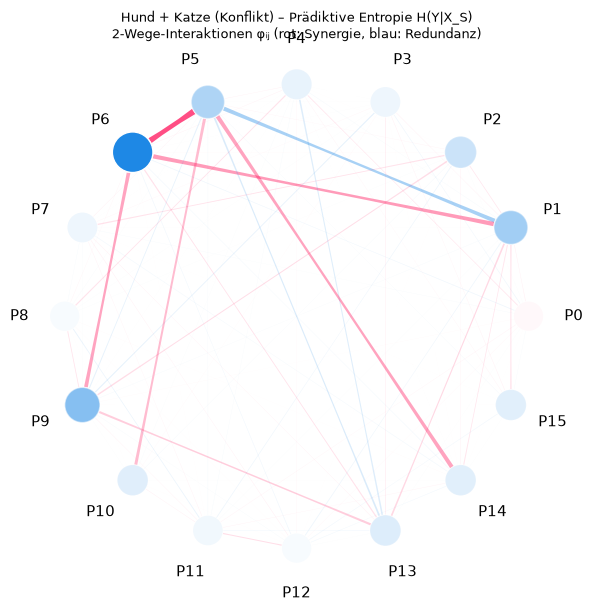

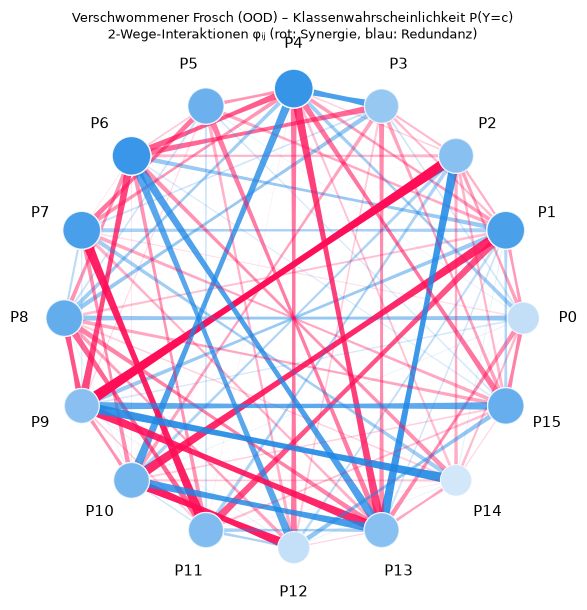

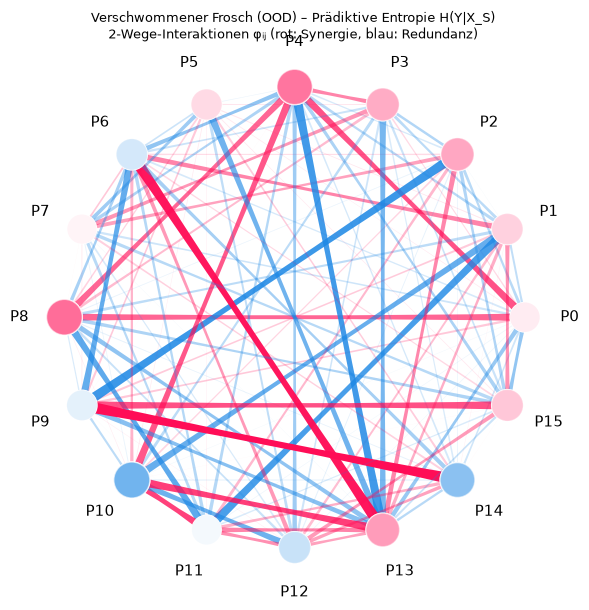

In [13]:
# 5.2 Interaktions-Netzwerke ---------------------------------------------------
names = [f"P{i}" for i in range(N_PLAYERS)]
for n in data:
    for m in MODES:
        iv = results[n][m]
        try:
            out = shapiq.network_plot(interaction_values=iv, feature_names=names, show=False)
            fig = out[0] if isinstance(out, tuple) else plt.gcf()
            fig.axes[0].set_title(f"{n} – {MODES[m]}\n2-Wege-Interaktionen φᵢⱼ (rot: Synergie, blau: Redundanz)", fontsize=9)
            plt.show()
        except Exception as e:  # Fallback: Interaktionsmatrix
            warnings.warn(f"network_plot fehlgeschlagen ({e}); zeige Matrix.")
            M = phi(iv)[1]; v = np.abs(M).max()
            plt.figure(figsize=(4.5, 4)); plt.imshow(M, cmap="bwr", vmin=-v, vmax=v); plt.colorbar()
            plt.title(f"{n} – {MODES[m]}", fontsize=9); plt.show()

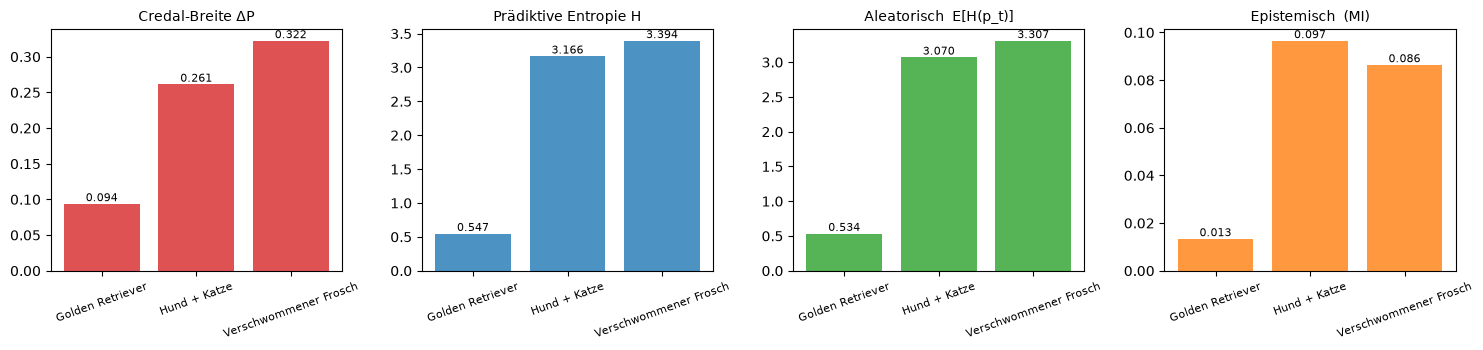

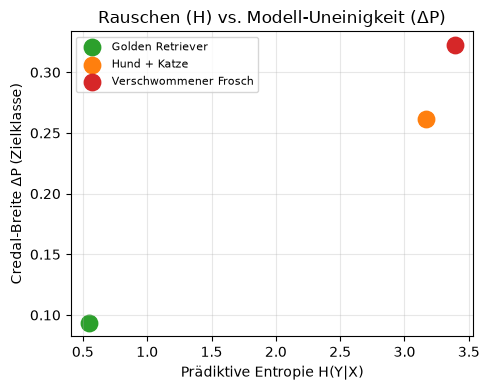

In [14]:
# 5.3 Credal-Breite vs. Entropie -------------------------------------------------
labels = [n.split(" (")[0] for n in data]
metrics = [("width", "Credal-Breite ΔP", "C3"), ("H", "Prädiktive Entropie H", "C0"),
           ("aleatoric", "Aleatorisch  E[H(p_t)]", "C2"), ("epistemic", "Epistemisch  (MI)", "C1")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for a, (k, t, c) in zip(axes, metrics):
    v = [summary[n][k] for n in data]
    a.bar(labels, v, color=c, alpha=.8)
    for i, x in enumerate(v): a.text(i, x, f"{x:.3f}", ha="center", va="bottom", fontsize=8)
    a.set_title(t, fontsize=10); a.tick_params(axis="x", labelrotation=20, labelsize=8)
plt.tight_layout(); plt.show()

fig, a = plt.subplots(figsize=(5, 4))
for n, c in zip(data, ["C2", "C1", "C3"]):
    a.scatter(summary[n]["H"], summary[n]["width"], s=140, c=c, label=n.split(" (")[0])
a.set_xlabel("Prädiktive Entropie H(Y|X)"); a.set_ylabel("Credal-Breite ΔP (Zielklasse)")
a.set_title("Rauschen (H) vs. Modell-Uneinigkeit (ΔP)"); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Section 6 – Zusammenfassung & Wissenschaftliche Interpretation
Die Zelle darunter fasst die gemessenen Kennzahlen automatisch zusammen. Die folgende Lesart ist als **Leitfaden mit Erwartungen** formuliert und muss an den tatsächlichen Zahlen und Heatmaps verifiziert werden:

- **High-Confidence (Golden Retriever):** Erwartet werden hohes $\bar p$, kleine Entropie und kleines $\Delta P$. Die Attributionen von $P(Y=c)$ sollten sich auf wenige objektbezeichnende Patches (Kopf/Fell) konzentrieren; für die Entropie sind die Beträge klein, da kaum Unsicherheit zu erklären ist.
- **Klassenkonflikt (Hund + Katze):** Erwartet werden mittleres $\bar p$ und erhöhte Entropie. Die Patches der beiden Objekte sollten gegensätzliche Vorzeichen im Entropie-Spiel zeigen. Positive Paar-Interaktionen *zwischen* den Objektregionen (Synergie) würden darauf hindeuten, dass erst die Kombination die Unsicherheit erzeugt. Ein erhöhtes $\Delta P$ zeigt zusätzlich Uneinigkeit der Dropout-Subnetze.
- **OOD / Blur (verschwommener Frosch):** Erwartet werden niedriges $\bar p$, hohe Entropie und tendenziell grösseres $\Delta P$ bzw. grössere MI. Attributionen sind oft diffus (viele Patches mit kleinen Beträgen), weil kein Bildbereich diskriminative Information liefert.
- **Entropie vs. Credal-Breite:** Beide Masse sind nicht redundant. Hohe $H$ bei kleinem $\Delta P$ ⇒ überwiegend aleatorisch (z. B. ambige, aber stabil ambige Szene); hohes $\Delta P$/MI ⇒ epistemische Modellunsicherheit.

**Limitationen:** (1) MC-Dropout ist nur eine Näherung der Posterior-Unsicherheit, und $p=0.3$ nachträglich auf vortrainierte Gewichte ist nicht kalibriert. (2) Min/Max über $T=30$ ist ein rauschbehafteter Credal-Schätzer. (3) Graue Imputation erzeugt Off-Manifold-Bilder; Attributionen sind relativ zu dieser Referenz zu lesen. (4) k-SII mit Budget 2000 von 65 536 Koalitionen ist eine Schätzung, Ergebnisse variieren leicht mit `SEED`/`BUDGET`. (5) Das $4\times4$-Gitter ist grob und schneidet Objekte willkürlich.

In [15]:
rows = []
for n, d in data.items():
    s, ph_p, ph_h = summary[n], phi(results[n]["prob"])[0], phi(results[n]["entropy"])[0]
    rows.append((n.split(" (")[0], CATEGORIES[d["target"]], s["p_mean"], s["width"], s["H"], s["epistemic"],
                 np.abs(ph_p).sum(), np.abs(ph_h).sum(),
                 np.sort(np.abs(ph_p).ravel())[::-1][:3].sum() / (np.abs(ph_p).sum() + 1e-12)))
hdr = ["Bild", "Klasse", "p̄", "ΔP", "H", "MI", "Σ|φ| prob", "Σ|φ| entr.", "Top-3-Anteil φ(prob)"]
print(" | ".join(hdr)); print("-" * 120)
for r in rows: print(f"{r[0]:22s} | {r[1][:22]:22s} | " + " | ".join(f"{v:.3f}" for v in r[2:]))
print("\nTop-3-Anteil: Konzentration der Attribution (nahe 1 = lokalisiert, klein = diffus).")

Bild | Klasse | p̄ | ΔP | H | MI | Σ|φ| prob | Σ|φ| entr. | Top-3-Anteil φ(prob)
------------------------------------------------------------------------------------------------------------------------
Golden Retriever       | golden retriever       | 0.927 | 0.094 | 0.547 | 0.013 | 1.478 | 13.049 | 0.710
Hund + Katze           | golden retriever       | 0.253 | 0.261 | 3.166 | 0.097 | 0.663 | 11.478 | 0.608
Verschwommener Frosch  | langur                 | 0.295 | 0.322 | 3.394 | 0.086 | 1.146 | 6.225 | 0.276

Top-3-Anteil: Konzentration der Attribution (nahe 1 = lokalisiert, klein = diffus).
